# Semana 5 Excepciones contratos y Result

Completar jerarquías de errores, una matrícula con contratos y un pipeline de Result que propague fallos esperados sin anidar resultados.

Identificador S5-001. Completar ApellidoNombre antes de entregar. Solución elaborada con asistencia de IA. No equivale a una sustentación realizada.


## Preparar archivos

Las celdas writefile guardan las fuentes visibles en el entorno de Colab. Ejecutarlas en orden. Se requiere Python 3.12 o superior y g++ con C++17.


In [ ]:
from pathlib import Path
for carpeta in ["python", "cpp", "tests", ".build", "evidencias"]:
    Path(carpeta).mkdir(exist_ok=True)


### python\__init__.py

In [ ]:
%%writefile python/__init__.py


### python\errores_hotel.py

In [ ]:
%%writefile python/errores_hotel.py
"""Errores del dominio hotelero y verificadores de contratos."""

from .hotel_base import Habitacion, Reserva
from .result import Result


class ErrorHotel(Exception):
    pass


class ErrorDatosHotel(ErrorHotel):
    pass


class ErrorEstadoReserva(ErrorHotel):
    pass


class ErrorDisponibilidad(ErrorHotel):
    pass


class HabitacionRobusta(Habitacion):
    def __init__(self, *args):
        try:
            super().__init__(*args)
        except (ValueError, RuntimeError) as causa:
            raise ErrorDatosHotel(str(causa)) from causa
        self._verificar_invariante()

    def _verificar_invariante(self):
        assert self.numero > 0 and self.tarifa > 0
        assert 0 <= self.plazas_libres <= self.capacidad

    def alojar(self, cantidad):
        try:
            super().alojar(cantidad)
        except (ValueError, RuntimeError) as causa:
            raise ErrorDisponibilidad(str(causa)) from causa
        self._verificar_invariante()


class ReservaRobusta(Reserva):
    def __init__(self, *args):
        try:
            super().__init__(*args)
        except (ValueError, RuntimeError) as causa:
            raise ErrorDatosHotel(str(causa)) from causa
        self._verificar_invariante()

    def _verificar_invariante(self):
        assert self.codigo.strip() and self.noches > 0
        assert self.estado in {"REGISTRADA", "CONFIRMADA", "ANULADA"}

    def confirmar(self):
        try:
            super().confirmar()
        except RuntimeError as causa:
            raise ErrorEstadoReserva(str(causa)) from causa
        self._verificar_invariante()

    def anular(self):
        try:
            super().anular()
        except RuntimeError as causa:
            raise ErrorEstadoReserva(str(causa)) from causa
        self._verificar_invariante()


def buscar_habitacion(habitaciones, numero):
    return next(
        (Result.ok(h) for h in habitaciones if h.numero == numero),
        Result.fallo("Habitacion no encontrada"),
    )


### python\excepciones.py

In [ ]:
%%writefile python/excepciones.py
"""Jerarquía académica con contexto y causas preservadas."""


class ErrorAcademico(Exception):
    def __init__(self, mensaje, contexto=None):
        super().__init__(mensaje)
        self.contexto = dict(contexto or {})

    def __str__(self):
        return super().__str__() + f" | contexto={self.contexto}"


class ErrorValidacion(ErrorAcademico):
    pass


class ErrorCalificacion(ErrorValidacion):
    def __init__(self, valor):
        super().__init__("Calificacion fuera de 0 a 20", {"valor": valor})
        self.valor_invalido = valor


class ErrorCapacidad(ErrorAcademico):
    def __init__(self, actual, maximo, entidad):
        super().__init__(
            "Capacidad invalida", {"actual": actual, "maximo": maximo, "entidad": entidad}
        )


class ErrorRecursoNoEncontrado(ErrorAcademico):
    def __init__(self, tipo, identificador):
        super().__init__("Recurso no encontrado", {"tipo": tipo, "id": identificador})


class ErrorMatriculaDuplicada(ErrorValidacion):
    def __init__(self, codigo):
        super().__init__("Matricula duplicada", {"codigo_estudiante": str(codigo)})
        self.codigo_estudiante = str(codigo)


def validar_matricula(codigo, matriculados):
    if codigo in matriculados:
        raise ErrorMatriculaDuplicada(codigo)


def cargar_nota_desde_archivo(ruta, codigo):
    try:
        with open(ruta, encoding="utf-8") as archivo:
            return float(archivo.read())
    except OSError as causa:
        raise ErrorRecursoNoEncontrado("Nota", codigo) from causa
    except ValueError as causa:
        raise ErrorValidacion("Contenido no numerico", {"ruta": str(ruta)}) from causa


### python\hotel_base.py

In [ ]:
%%writefile python/hotel_base.py
"""Modelo inicial del proyecto hotelero correspondiente a la semana 2."""

from datetime import date
from math import isfinite


def texto(valor):
    if not isinstance(valor, str) or not valor.strip():
        raise ValueError("Texto no vacio requerido")
    return valor


def entero(valor, minimo, maximo):
    if type(valor) is not int or not minimo <= valor <= maximo:
        raise ValueError("Entero fuera de rango")
    return valor


class Huesped:
    def __init__(self, identificador, nombre, documento):
        self.__id = texto(identificador)
        self.nombre = nombre
        self.documento = documento

    @property
    def id(self):
        return self.__id

    @property
    def nombre(self):
        return self.__nombre

    @nombre.setter
    def nombre(self, valor):
        self.__nombre = texto(valor)

    @property
    def documento(self):
        return self.__documento

    @documento.setter
    def documento(self, valor):
        if (
            not isinstance(valor, str)
            or len(valor) != 8
            or not valor.isascii()
            or not valor.isdigit()
        ):
            raise ValueError("DNI debe tener ocho digitos ASCII")
        self.__documento = valor

    @property
    def etiqueta(self):
        return f"{self.id} {self.nombre}"

    def actualizar_documento(self, documento):
        self.documento = documento


class Habitacion:
    def __init__(self, numero, tipo, capacidad, tarifa):
        self.__numero = entero(numero, 1, 9999)
        self.__ocupantes = 0
        self.tipo = tipo
        self.capacidad = capacidad
        self.tarifa = tarifa

    @property
    def numero(self):
        return self.__numero

    @property
    def tipo(self):
        return self.__tipo

    @tipo.setter
    def tipo(self, valor):
        self.__tipo = texto(valor)

    @property
    def capacidad(self):
        return self.__capacidad

    @capacidad.setter
    def capacidad(self, valor):
        entero(valor, 1, 10)
        if valor < self.__ocupantes:
            raise ValueError("Capacidad menor que ocupantes")
        self.__capacidad = valor

    @property
    def tarifa(self):
        return self.__tarifa

    @tarifa.setter
    def tarifa(self, valor):
        if (
            isinstance(valor, bool)
            or not isinstance(valor, (float, int))
            or not isfinite(valor)
            or valor <= 0
        ):
            raise ValueError("Tarifa positiva finita requerida")
        self.__tarifa = float(valor)

    @property
    def plazas_libres(self):
        return self.capacidad - self.__ocupantes

    def alojar(self, cantidad):
        entero(cantidad, 1, 10)
        if cantidad > self.plazas_libres:
            raise RuntimeError("Sin plazas")
        self.__ocupantes += cantidad

    def liberar(self):
        self.__ocupantes = 0

    def precio_noche(self):
        return self.tarifa


class Reserva:
    def __init__(self, codigo, entrada, salida):
        self.__codigo = texto(codigo)
        self.__entrada = date.fromisoformat(entrada)
        self.__salida = date.fromisoformat(salida)
        if self.__salida <= self.__entrada:
            raise ValueError("Salida debe ser posterior")
        self.__estado = "REGISTRADA"

    @property
    def codigo(self):
        return self.__codigo

    @property
    def entrada(self):
        return self.__entrada.isoformat()

    @property
    def salida(self):
        return self.__salida.isoformat()

    @property
    def noches(self):
        return (self.__salida - self.__entrada).days

    @property
    def estado(self):
        return self.__estado

    def confirmar(self):
        if self.estado != "REGISTRADA":
            raise RuntimeError("Confirmacion no permitida")
        self.__estado = "CONFIRMADA"

    def anular(self):
        if self.estado == "ANULADA":
            raise RuntimeError("Reserva ya anulada")
        self.__estado = "ANULADA"


### python\hotel_herencia.py

In [ ]:
%%writefile python/hotel_herencia.py
"""Semana 3: las categorías son habitaciones y conservan el contrato de precio."""

from .hotel_base import Habitacion


class HabitacionSimple(Habitacion):
    def __init__(self, numero, tarifa=100):
        super().__init__(numero, "Simple", 1, tarifa)

    def precio_noche(self):
        return self.tarifa


class HabitacionDoble(Habitacion):
    def __init__(self, numero, tarifa=100):
        super().__init__(numero, "Doble", 2, tarifa)

    def precio_noche(self):
        return self.tarifa * 1.5


class Suite(Habitacion):
    def __init__(self, numero, tarifa=100):
        super().__init__(numero, "Suite", 4, tarifa)

    def precio_noche(self):
        return self.tarifa * 2


def cotizar_habitaciones(habitaciones):
    return [h.precio_noche() for h in habitaciones]


### python\main.py

In [ ]:
%%writefile python/main.py
from .solucion import demo

if __name__ == "__main__":
    print("\n".join(demo()))


### python\result.py

In [ ]:
%%writefile python/result.py
"""Result inmutable y discriminado; map encadena funciones que retornan Result."""

from dataclasses import dataclass
from typing import Generic, TypeVar, Callable

T = TypeVar("T")
U = TypeVar("U")


@dataclass(frozen=True)
class Result(Generic[T]):
    _exito: bool
    _dato: object

    def __post_init__(self):
        if type(self._exito) is not bool:
            raise TypeError("Discriminante booleano requerido")
        if not self._exito and (not isinstance(self._dato, str) or not self._dato):
            raise ValueError("Mensaje de error requerido")

    @staticmethod
    def ok(valor: T) -> "Result[T]":
        return Result(True, valor)

    @staticmethod
    def fallo(error: str) -> "Result[T]":
        return Result(False, error)

    @property
    def es_exito(self):
        return self._exito

    @property
    def valor(self) -> T:
        if not self.es_exito:
            raise RuntimeError("Result fallido: " + str(self._dato))
        return self._dato

    @property
    def error(self):
        if self.es_exito:
            raise RuntimeError("Un exito no tiene error")
        return self._dato

    def map(self, f: Callable[[T], "Result[U]"]) -> "Result[U]":
        if not self.es_exito:
            return Result.fallo(self.error)
        resultado = f(self.valor)
        if not isinstance(resultado, Result):
            raise TypeError("map espera una funcion que retorne Result")
        return resultado


### python\solucion.py

In [ ]:
%%writefile python/solucion.py
"""Matrícula por contrato y pipeline de fallos esperados."""

from datetime import date
from .excepciones import *
from .result import Result


class Matricula:
    MAX_CURSOS = 6

    def __init__(self, codigo, cursos, fecha=None):
        fecha = date.today() if fecha is None else fecha
        if not codigo.strip():
            raise ErrorValidacion("Codigo vacio")
        if not 1 <= len(cursos) <= 6:
            raise ErrorCapacidad(len(cursos), 6, "matricula")
        if len(set(cursos)) != len(cursos) or any(not c.strip() for c in cursos):
            raise ErrorValidacion("Cursos vacios o repetidos")
        if type(fecha) is not date or fecha > date.today():
            raise ErrorValidacion("Fecha invalida o futura")
        self._codigo_estudiante, self._cursos, self._fecha, self._anulada = (
            codigo,
            list(cursos),
            fecha,
            False,
        )
        self._verificar_invariante()

    @property
    def cursos(self):
        return tuple(self._cursos)

    @property
    def anulada(self):
        return self._anulada

    def _verificar_invariante(self):
        assert self._codigo_estudiante.strip()
        assert 1 <= len(self._cursos) <= 6 and len(set(self._cursos)) == len(self._cursos)
        assert all(c.strip() for c in self._cursos)
        assert self._fecha <= date.today()

    def _puede_modificar(self):
        if self._anulada:
            raise ErrorAcademico("Matricula anulada")

    def agregar_curso(self, curso):
        self._puede_modificar()
        if not curso.strip() or curso in self._cursos:
            raise ErrorValidacion("Curso vacio o repetido")
        if len(self._cursos) >= 6:
            raise ErrorCapacidad(len(self._cursos), 6, "matricula")
        self._cursos.append(curso)
        assert self._cursos[-1] == curso
        self._verificar_invariante()

    def eliminar_curso(self, curso):
        self._puede_modificar()
        if curso not in self._cursos:
            raise ErrorRecursoNoEncontrado("Curso", curso)
        if len(self._cursos) == 1:
            raise ErrorValidacion("Debe quedar al menos un curso")
        self._cursos.remove(curso)
        assert curso not in self._cursos
        self._verificar_invariante()

    def anular(self):
        self._puede_modificar()
        self._anulada = True
        self._verificar_invariante()

    def diagnostico(self):
        try:
            self._verificar_invariante()
            return f"Matricula OK {len(self._cursos)}/6"
        except AssertionError:
            return "Matricula INVALIDA"


def buscar_estudiante(codigo):
    return (
        Result.ok({"codigo": 1001, "nombre": "Juan Mamani", "ppa": 15.0})
        if codigo == 1001
        else Result.fallo("Estudiante no encontrado")
    )


def validar_ppa_minimo(estudiante):
    return Result.ok(estudiante) if estudiante["ppa"] >= 14 else Result.fallo("PPA insuficiente")


def inscribir(estudiante, curso):
    return Result.ok(f"Inscrito: {estudiante['nombre']} en {curso}")


def pipeline(codigo):
    return buscar_estudiante(codigo).map(validar_ppa_minimo).map(lambda e: inscribir(e, "SIS206"))


def demo():
    m = Matricula("20210500", ["SIS206"])
    m.agregar_curso("SIS207")
    m.eliminar_curso("SIS207")
    return [
        f"CURSOS={len(m.cursos)}",
        f"EXITO={pipeline(1001).valor}",
        f"FALLO={pipeline(9999).error}",
    ]


### cpp\comun.hpp

In [ ]:
%%writefile cpp/comun.hpp
#pragma once
#include <algorithm>
#include <cassert>
#include <cmath>
#include <ctime>
#include <functional>
#include <iomanip>
#include <iostream>
#include <memory>
#include <regex>
#include <sstream>
#include <stdexcept>
#include <string>
#include <utility>
#include <vector>

inline void exigir(bool condicion) {
    if (!condicion) {
        throw std::runtime_error("No coincide con el contrato esperado");
    }
}
template <class Error = std::exception, class F> void debeFallar(F accion) {
    bool fallo = false;
    try {
        accion();
    } catch (const Error &) {
        fallo = true;
    }
    exigir(fallo);
}
struct Pruebas {
    int total = 0, correctas = 0;
    template <class F> void caso(const std::string &nombre, F accion) {
        ++total;
        try {
            accion();
            ++correctas;
            std::cout << "OK " << nombre << '\n';
        } catch (const std::exception &e) {
            std::cerr << "FALLO " << nombre << ": " << e.what() << '\n';
        }
    }
    int terminar() const {
        std::cout << correctas << '/' << total << " pruebas aprobadas\n";
        return total == correctas ? 0 : 1;
    }
};
inline void textoValido(const std::string &v) {
    if (v.find_first_not_of(" \t\r\n") == std::string::npos) {
        throw std::invalid_argument("Texto vacio");
    }
}
inline void positivo(double v) {
    if (!std::isfinite(v) || v <= 0) {
        throw std::invalid_argument("Valor positivo requerido");
    }
}
inline bool bisiesto(int y) {
    return y % 4 == 0 && (y % 100 != 0 || y % 400 == 0);
}
inline int ordinal(const std::string &fecha) {
    if (!std::regex_match(fecha, std::regex("[0-9]{4}-[0-9]{2}-[0-9]{2}"))) {
        throw std::invalid_argument("Fecha ISO requerida");
    }
    int y = std::stoi(fecha.substr(0, 4)), m = std::stoi(fecha.substr(5, 2)),
        d = std::stoi(fecha.substr(8, 2));
    const int dias[] = {31, 28, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31};
    if (y < 1 || m < 1 || m > 12 || d < 1 || d > dias[m - 1] + (m == 2 && bisiesto(y))) {
        throw std::invalid_argument("Fecha inexistente");
    }
    int n = 365 * (y - 1) + (y - 1) / 4 - (y - 1) / 100 + (y - 1) / 400 + d;
    for (int i = 1; i < m; ++i) {
        n += dias[i - 1] + (i == 2 && bisiesto(y));
    }
    return n;
}
inline std::string hoyISO() {
    auto ahora = std::time(nullptr);
    auto *fecha = std::localtime(&ahora);
    if (!fecha) {
        throw std::runtime_error("Reloj no disponible");
    }
    std::ostringstream out;
    out << std::put_time(fecha, "%Y-%m-%d");
    return out.str();
}


### cpp\errores_academicos.hpp

In [ ]:
%%writefile cpp/errores_academicos.hpp
#pragma once
#include "comun.hpp"
class ErrorAcademico : public std::runtime_error {
  public:
    using std::runtime_error::runtime_error;
    virtual ~ErrorAcademico() = default;
};
class ErrorValidacion : public ErrorAcademico {
  public:
    using ErrorAcademico::ErrorAcademico;
};
class ErrorCalificacion : public ErrorValidacion {
    double valor_;

  public:
    explicit ErrorCalificacion(double valor)
        : ErrorValidacion("Calificacion fuera de rango"), valor_(valor) {}
    double valor() const noexcept {
        return valor_;
    }
};
class ErrorCapacidad : public ErrorAcademico {
    int actual_, maximo_;

  public:
    ErrorCapacidad(int actual, int maximo)
        : ErrorAcademico("Capacidad invalida"), actual_(actual), maximo_(maximo) {}
    int actual() const noexcept {
        return actual_;
    }
    int maximo() const noexcept {
        return maximo_;
    }
};
class ErrorRecursoNoEncontrado : public ErrorAcademico {
  public:
    using ErrorAcademico::ErrorAcademico;
};
class ErrorMatriculaDuplicada : public ErrorValidacion {
    std::string codigo_;

  public:
    explicit ErrorMatriculaDuplicada(std::string codigo)
        : ErrorValidacion("Matricula duplicada"), codigo_(std::move(codigo)) {}
    const std::string &codigoEstudiante() const noexcept {
        return codigo_;
    }
};
inline void validarMatricula(int codigo, std::vector<int> &matriculados) {
    if (std::find(matriculados.begin(), matriculados.end(), codigo) != matriculados.end()) {
        throw ErrorMatriculaDuplicada(std::to_string(codigo));
    }
}


### cpp\errores_hotel.hpp

In [ ]:
%%writefile cpp/errores_hotel.hpp
#pragma once
#include "hotel_base.hpp"
#include "result.hpp"
class ErrorHotel : public std::runtime_error {
  public:
    using std::runtime_error::runtime_error;
    virtual ~ErrorHotel() = default;
};
class ErrorDatosHotel : public ErrorHotel {
  public:
    using ErrorHotel::ErrorHotel;
};
class ErrorEstadoReserva : public ErrorHotel {
  public:
    using ErrorHotel::ErrorHotel;
};
class ErrorDisponibilidad : public ErrorHotel {
  public:
    using ErrorHotel::ErrorHotel;
};
class HabitacionRobusta : public Habitacion {
  public:
    HabitacionRobusta(int numero, const std::string &tipo, int capacidad, double tarifa) try
        : Habitacion(numero, tipo, capacidad, tarifa) {
        verificarInvariante();
    } catch (const std::invalid_argument &e) {
        throw ErrorDatosHotel(e.what());
    }
    void verificarInvariante() const {
        assert(numero() > 0 && tarifa() > 0);
        assert(plazasLibres() >= 0 && plazasLibres() <= capacidad());
    }
    void alojar(int n) {
        try {
            Habitacion::alojar(n);
        } catch (const std::runtime_error &e) {
            throw ErrorDisponibilidad(e.what());
        }
        verificarInvariante();
    }
};
class ReservaRobusta : public Reserva {
  public:
    ReservaRobusta(const std::string &codigo, const std::string &entrada,
                   const std::string &salida) try
        : Reserva(codigo, entrada, salida) {
        verificarInvariante();
    } catch (const std::invalid_argument &e) {
        throw ErrorDatosHotel(e.what());
    }
    void verificarInvariante() const {
        assert(!codigo().empty() && noches() > 0);
    }
    void confirmar() {
        try {
            Reserva::confirmar();
        } catch (const std::runtime_error &e) {
            throw ErrorEstadoReserva(e.what());
        }
        verificarInvariante();
    }
    void anular() {
        try {
            Reserva::anular();
        } catch (const std::runtime_error &e) {
            throw ErrorEstadoReserva(e.what());
        }
        verificarInvariante();
    }
};
inline Result<std::shared_ptr<Habitacion>>
buscarHabitacion(const std::vector<std::shared_ptr<Habitacion>> &hs, int numero) {
    for (const auto &h : hs) {
        if (h && h->numero() == numero) {
            return Result<std::shared_ptr<Habitacion>>::ok(h);
        }
    }
    return Result<std::shared_ptr<Habitacion>>::fallo("Habitacion no encontrada");
}


### cpp\hotel_base.hpp

In [ ]:
%%writefile cpp/hotel_base.hpp
#pragma once
#include "comun.hpp"

class Huesped {
    std::string id_, nombre_, documento_;

  public:
    Huesped(std::string id, std::string nombre, std::string documento) : id_(std::move(id)) {
        textoValido(id_);
        setNombre(nombre);
        setDocumento(documento);
    }
    const std::string &id() const noexcept {
        return id_;
    }
    const std::string &nombre() const noexcept {
        return nombre_;
    }
    const std::string &documento() const noexcept {
        return documento_;
    }
    void setNombre(const std::string &v) {
        textoValido(v);
        nombre_ = v;
    }
    void setDocumento(const std::string &v) {
        if (!std::regex_match(v, std::regex("[0-9]{8}"))) {
            throw std::invalid_argument("DNI invalido");
        }
        documento_ = v;
    }
    std::string etiqueta() const {
        return id_ + " " + nombre_;
    }
    void actualizarDocumento(const std::string &v) {
        setDocumento(v);
    }
};

class Habitacion {
    int numero_, capacidad_ = 1, ocupantes_ = 0;
    std::string tipo_;
    double tarifa_ = 1;

  public:
    Habitacion(int numero, const std::string &tipo, int capacidad, double tarifa)
        : numero_(numero) {
        if (numero < 1 || numero > 9999) {
            throw std::invalid_argument("Numero invalido");
        }
        setTipo(tipo);
        setCapacidad(capacidad);
        setTarifa(tarifa);
    }
    virtual ~Habitacion() = default;
    int numero() const noexcept {
        return numero_;
    }
    int capacidad() const noexcept {
        return capacidad_;
    }
    const std::string &tipo() const noexcept {
        return tipo_;
    }
    double tarifa() const noexcept {
        return tarifa_;
    }
    void setTipo(const std::string &v) {
        textoValido(v);
        tipo_ = v;
    }
    void setCapacidad(int v) {
        if (v < 1 || v > 10 || v < ocupantes_) {
            throw std::invalid_argument("Capacidad invalida");
        }
        capacidad_ = v;
    }
    void setTarifa(double v) {
        positivo(v);
        tarifa_ = v;
    }
    int plazasLibres() const noexcept {
        return capacidad_ - ocupantes_;
    }
    void alojar(int cantidad) {
        if (cantidad <= 0 || cantidad > plazasLibres()) {
            throw std::runtime_error("Sin plazas");
        }
        ocupantes_ += cantidad;
    }
    void liberar() noexcept {
        ocupantes_ = 0;
    }
    virtual double precioNoche() const {
        return tarifa_;
    }
};

class Reserva {
    std::string codigo_, entrada_, salida_, estado_ = "REGISTRADA";

  public:
    Reserva(std::string codigo, std::string entrada, std::string salida)
        : codigo_(std::move(codigo)), entrada_(std::move(entrada)), salida_(std::move(salida)) {
        textoValido(codigo_);
        if (ordinal(salida_) <= ordinal(entrada_)) {
            throw std::invalid_argument("Salida debe ser posterior");
        }
    }
    const std::string &codigo() const noexcept {
        return codigo_;
    }
    const std::string &entrada() const noexcept {
        return entrada_;
    }
    const std::string &salida() const noexcept {
        return salida_;
    }
    const std::string &estado() const noexcept {
        return estado_;
    }
    int noches() const {
        return ordinal(salida_) - ordinal(entrada_);
    }
    void confirmar() {
        if (estado_ != "REGISTRADA") {
            throw std::runtime_error("Confirmacion no permitida");
        }
        estado_ = "CONFIRMADA";
    }
    void anular() {
        if (estado_ == "ANULADA") {
            throw std::runtime_error("Reserva ya anulada");
        }
        estado_ = "ANULADA";
    }
};


### cpp\hotel_herencia.hpp

In [ ]:
%%writefile cpp/hotel_herencia.hpp
#pragma once
#include "hotel_base.hpp"
class HabitacionSimple : public Habitacion {
  public:
    explicit HabitacionSimple(int numero, double tarifa = 100)
        : Habitacion(numero, "Simple", 1, tarifa) {}
    double precioNoche() const override {
        return tarifa();
    }
};
class HabitacionDoble : public Habitacion {
  public:
    explicit HabitacionDoble(int numero, double tarifa = 100)
        : Habitacion(numero, "Doble", 2, tarifa) {}
    double precioNoche() const override {
        return tarifa() * 1.5;
    }
};
class Suite : public Habitacion {
  public:
    explicit Suite(int numero, double tarifa = 100) : Habitacion(numero, "Suite", 4, tarifa) {}
    double precioNoche() const override {
        return tarifa() * 2;
    }
};


### cpp\main.cpp

In [ ]:
%%writefile cpp/main.cpp
#include "solucion.hpp"
int main() {
    demo();
}


### cpp\matricula.hpp

In [ ]:
%%writefile cpp/matricula.hpp
#pragma once
#include "errores_academicos.hpp"
#include <set>
class Matricula {
    std::string codigo_, fecha_;
    std::vector<std::string> cursos_;
    bool anulada_ = false;
    void puedeModificar() const {
        if (anulada_) {
            throw ErrorAcademico("Matricula anulada");
        }
    }
    void verificarInvariante() const {
        assert(!codigo_.empty());
        assert(cursos_.size() >= 1 && cursos_.size() <= 6);
        assert(std::set<std::string>(cursos_.begin(), cursos_.end()).size() == cursos_.size());
        assert(ordinal(fecha_) <= ordinal(hoyISO()));
    }

  public:
    Matricula(std::string codigo, std::vector<std::string> cursos, std::string fecha = hoyISO())
        : codigo_(std::move(codigo)), fecha_(std::move(fecha)), cursos_(std::move(cursos)) {
        if (codigo_.find_first_not_of(" \t\r\n") == std::string::npos) {
            throw ErrorValidacion("Codigo vacio");
        }
        if (cursos_.empty() || cursos_.size() > 6) {
            throw ErrorCapacidad(static_cast<int>(cursos_.size()), 6);
        }
        if (std::set<std::string>(cursos_.begin(), cursos_.end()).size() != cursos_.size()) {
            throw ErrorValidacion("Duplicados");
        }
        for (const auto &c : cursos_) {
            if (c.find_first_not_of(" \t\r\n") == std::string::npos) {
                throw ErrorValidacion("Curso vacio");
            }
        }
        if (ordinal(fecha_) > ordinal(hoyISO())) {
            throw ErrorValidacion("Fecha futura");
        }
        verificarInvariante();
    }
    void agregarCurso(const std::string &curso) {
        puedeModificar();
        if (curso.find_first_not_of(" \t\r\n") == std::string::npos ||
            std::find(cursos_.begin(), cursos_.end(), curso) != cursos_.end()) {
            throw ErrorValidacion("Curso vacio o repetido");
        }
        if (cursos_.size() >= 6) {
            throw ErrorCapacidad(static_cast<int>(cursos_.size()), 6);
        }
        cursos_.push_back(curso);
        assert(cursos_.back() == curso);
        verificarInvariante();
    }
    void eliminarCurso(const std::string &curso) {
        puedeModificar();
        auto it = std::find(cursos_.begin(), cursos_.end(), curso);
        if (it == cursos_.end()) {
            throw ErrorRecursoNoEncontrado("Curso inexistente");
        }
        if (cursos_.size() == 1) {
            throw ErrorValidacion("Debe quedar al menos un curso");
        }
        cursos_.erase(it);
        assert(std::find(cursos_.begin(), cursos_.end(), curso) == cursos_.end());
        verificarInvariante();
    }
    void anular() {
        puedeModificar();
        anulada_ = true;
        verificarInvariante();
    }
    int numCursos() const noexcept {
        return static_cast<int>(cursos_.size());
    }
    bool anulada() const noexcept {
        return anulada_;
    }
    const auto &cursos() const noexcept {
        return cursos_;
    }
    std::string diagnostico() const {
        return "Matricula OK " + std::to_string(cursos_.size()) + "/6";
    }
};


### cpp\pruebas.cpp

In [ ]:
%%writefile cpp/pruebas.cpp
#include "errores_hotel.hpp"
#include "solucion.hpp"
int main() {
    Pruebas t;
    t.caso("constructor valido", [] {
        Matricula m("E1", {"SIS206"});
        exigir(m.numCursos() == 1);
    });
    t.caso("sin cursos", [] { debeFallar<ErrorCapacidad>([] { Matricula m("E1", {}); }); });
    t.caso("maximo seis", [] {
        debeFallar<ErrorCapacidad>([] { Matricula m("E1", {"1", "2", "3", "4", "5", "6", "7"}); });
    });
    t.caso("duplicados",
           [] { debeFallar<ErrorValidacion>([] { Matricula m("E1", {"SIS206", "SIS206"}); }); });
    t.caso("fecha futura", [] {
        debeFallar<ErrorValidacion>([] { Matricula m("E1", {"SIS206"}, "9999-12-31"); });
    });
    t.caso("agregar y eliminar", [] {
        Matricula m("E1", {"SIS206"});
        m.agregarCurso("SIS207");
        m.eliminarCurso("SIS207");
        exigir(m.numCursos() == 1);
    });
    t.caso("ultimo curso", [] {
        Matricula m("E1", {"SIS206"});
        debeFallar<ErrorValidacion>([&] { m.eliminarCurso("SIS206"); });
        exigir(m.numCursos() == 1);
    });
    t.caso("anulada", [] {
        Matricula m("E1", {"SIS206"});
        m.anular();
        debeFallar<ErrorAcademico>([&] { m.agregarCurso("SIS207"); });
    });
    t.caso("diagnostico", [] {
        Matricula m("E1", {"SIS206"});
        exigir(m.diagnostico().find("OK") != std::string::npos);
    });
    t.caso("duplicada con contexto", [] {
        std::vector<int> ids = {1001};
        try {
            validarMatricula(1001, ids);
            exigir(false);
        } catch (const ErrorMatriculaDuplicada &e) {
            exigir(e.codigoEstudiante() == "1001");
        }
    });
    t.caso("captura especifica", [] {
        bool capturado = false;
        try {
            throw ErrorCalificacion(25);
        } catch (const ErrorCalificacion &e) {
            capturado = e.valor() == 25;
        } catch (const ErrorAcademico &) {
            exigir(false);
        }
        exigir(capturado);
    });
    t.caso("result string", [] {
        exigir(Result<std::string>::ok("valor").valor() == "valor");
        exigir(Result<std::string>::fallo("error").error() == "error");
    });
    t.caso("acceso invalido",
           [] { debeFallar<std::logic_error>([] { Result<int>::fallo("error").valor(); }); });
    t.caso("pipeline", [] { exigir(pipeline(1001).esExito() && !pipeline(9999).esExito()); });
    t.caso("cortocircuito", [] {
        bool llamado = false;
        auto r = Result<int>::fallo("error").map([&](int n) {
            llamado = true;
            return Result<int>::ok(n);
        });
        exigir(!r.esExito() && !llamado);
    });
    t.caso("ppa insuficiente", [] { exigir(!validarPpaMinimo({"Ana", 10}).esExito()); });
    t.caso("hotel valido habitacion", [] {
        HabitacionRobusta h(101, "Doble", 2, 100);
        h.alojar(1);
        h.verificarInvariante();
        exigir(h.plazasLibres() == 1);
    });
    t.caso("hotel valida reserva", [] {
        ReservaRobusta r("R1", "2026-10-18", "2026-10-20");
        r.confirmar();
        r.verificarInvariante();
        exigir(r.noches() == 2);
    });
    t.caso("hotel result", [] { exigir(!buscarHabitacion({}, 101).esExito()); });
    t.caso("hotel constructor invalido",
           [] { debeFallar<ErrorDatosHotel>([] { HabitacionRobusta h(101, "Doble", 0, 100); }); });
    t.caso("hotel sin plazas", [] {
        HabitacionRobusta h(101, "Doble", 2, 100);
        debeFallar<ErrorDisponibilidad>([&] { h.alojar(3); });
    });
    t.caso("hotel estado", [] {
        ReservaRobusta r("R1", "2026-10-18", "2026-10-20");
        r.anular();
        debeFallar<ErrorEstadoReserva>([&] { r.confirmar(); });
    });
    return t.terminar();
}


### cpp\result.hpp

In [ ]:
%%writefile cpp/result.hpp
#pragma once
#include "comun.hpp"
#include <variant>
struct FalloResult {
    std::string mensaje;
};
template <class T> class Result {
    std::variant<T, FalloResult> dato_;
    Result(std::in_place_index_t<0>, T valor) : dato_(std::in_place_index<0>, std::move(valor)) {}
    Result(std::in_place_index_t<1>, std::string error)
        : dato_(std::in_place_index<1>, FalloResult{std::move(error)}) {}

  public:
    static Result ok(T valor) {
        return Result(std::in_place_index<0>, std::move(valor));
    }
    static Result fallo(std::string mensaje) {
        textoValido(mensaje);
        return Result(std::in_place_index<1>, std::move(mensaje));
    }
    bool esExito() const noexcept {
        return dato_.index() == 0;
    }
    const T &valor() const {
        if (!esExito()) {
            throw std::logic_error("Result fallido");
        }
        return std::get<0>(dato_);
    }
    const std::string &error() const {
        if (esExito()) {
            throw std::logic_error("Un exito no tiene error");
        }
        return std::get<1>(dato_).mensaje;
    }
    template <class F> auto map(F funcion) const -> decltype(funcion(std::declval<const T &>())) {
        using Resultado = decltype(funcion(std::declval<const T &>()));
        if (!esExito()) {
            return Resultado::fallo(error());
        }
        return funcion(valor());
    }
};


### cpp\solucion.hpp

In [ ]:
%%writefile cpp/solucion.hpp
#pragma once
#include "matricula.hpp"
#include "result.hpp"
struct EstudiantePipeline {
    std::string nombre;
    double ppa;
};
inline Result<EstudiantePipeline> buscarEstudiante(int codigo) {
    return codigo == 1001 ? Result<EstudiantePipeline>::ok({"Juan Mamani", 15})
                          : Result<EstudiantePipeline>::fallo("Estudiante no encontrado");
}
inline Result<EstudiantePipeline> validarPpaMinimo(const EstudiantePipeline &est) {
    return est.ppa >= 14 ? Result<EstudiantePipeline>::ok(est)
                         : Result<EstudiantePipeline>::fallo("PPA insuficiente");
}
inline Result<std::string> inscribir(const EstudiantePipeline &est, const std::string &curso) {
    return Result<std::string>::ok("Inscrito: " + est.nombre + " en " + curso);
}
inline Result<std::string> pipeline(int codigo) {
    return buscarEstudiante(codigo).map(validarPpaMinimo).map([](const EstudiantePipeline &e) {
        return inscribir(e, "SIS206");
    });
}
inline void demo() {
    Matricula m("20210500", {"SIS206"});
    m.agregarCurso("SIS207");
    m.eliminarCurso("SIS207");
    std::cout << "CURSOS=" << m.numCursos() << "\nEXITO=" << pipeline(1001).valor()
              << "\nFALLO=" << pipeline(9999).error() << '\n';
}


### tests\__init__.py

In [ ]:
%%writefile tests/__init__.py


### tests\test_solucion.py

In [ ]:
%%writefile tests/test_solucion.py
import unittest
from datetime import date, timedelta
from pathlib import Path
from tempfile import TemporaryDirectory
from python.solucion import Matricula, pipeline, validar_ppa_minimo
from python.excepciones import *
from python.result import Result
from python.errores_hotel import *


class ContratosSemana5(unittest.TestCase):
    def test_constructor_valido(self):
        self.assertEqual(Matricula("E1", ["SIS206"]).cursos, ("SIS206",))

    def test_sin_cursos(self):
        with self.assertRaises(ErrorCapacidad):
            Matricula("E1", [])

    def test_maximo_seis(self):
        with self.assertRaises(ErrorCapacidad):
            Matricula("E1", [str(n) for n in range(7)])

    def test_duplicados(self):
        with self.assertRaises(ErrorValidacion):
            Matricula("E1", ["SIS206", "SIS206"])

    def test_fecha_futura(self):
        with self.assertRaises(ErrorValidacion):
            Matricula("E1", ["SIS206"], date.today() + timedelta(days=1))

    def test_agregar_y_eliminar(self):
        m = Matricula("E1", ["SIS206"])
        m.agregar_curso("SIS207")
        m.eliminar_curso("SIS207")
        self.assertEqual(m.cursos, ("SIS206",))

    def test_no_eliminar_ultimo(self):
        m = Matricula("E1", ["SIS206"])
        with self.assertRaises(ErrorValidacion):
            m.eliminar_curso("SIS206")
        self.assertEqual(len(m.cursos), 1)

    def test_anular_impide_modificar(self):
        m = Matricula("E1", ["SIS206"])
        m.anular()
        with self.assertRaises(ErrorAcademico):
            m.agregar_curso("SIS207")
        with self.assertRaises(ErrorAcademico):
            m.eliminar_curso("SIS206")

    def test_diagnostico_e_invariante(self):
        self.assertIn("OK", Matricula("E1", ["SIS206"]).diagnostico())

    def test_matricula_duplicada_contexto(self):
        with self.assertRaises(ErrorMatriculaDuplicada) as c:
            validar_matricula(1001, [1001])
        self.assertEqual(c.exception.codigo_estudiante, "1001")
        self.assertIsInstance(c.exception, ErrorValidacion)

    def test_causa_preservada(self):
        with TemporaryDirectory() as d:
            with self.assertRaises(ErrorRecursoNoEncontrado) as c:
                cargar_nota_desde_archivo(Path(d) / "ausente", 1001)
            self.assertIsInstance(c.exception.__cause__, OSError)

    def test_result_string_exito_y_fallo(self):
        self.assertEqual(Result.ok("valor").valor, "valor")
        self.assertEqual(Result.fallo("error").error, "error")

    def test_result_impide_acceso_incorrecto(self):
        with self.assertRaises(RuntimeError):
            _ = Result.fallo("error").valor
        with self.assertRaises(RuntimeError):
            _ = Result.ok("ok").error

    def test_pipeline_exito_y_fallo(self):
        self.assertTrue(pipeline(1001).es_exito)
        self.assertFalse(pipeline(9999).es_exito)

    def test_cortocircuito(self):
        llamadas = []
        r = Result.fallo("error").map(lambda x: llamadas.append(x))
        self.assertFalse(r.es_exito)
        self.assertEqual(llamadas, [])

    def test_ppa_insuficiente(self):
        self.assertFalse(validar_ppa_minimo({"ppa": 10}).es_exito)

    def test_hotel_valido_habitacion(self):
        h = HabitacionRobusta(101, "Doble", 2, 100)
        h.alojar(1)
        h._verificar_invariante()
        self.assertEqual(h.plazas_libres, 1)

    def test_hotel_valida_reserva(self):
        r = ReservaRobusta("R1", "2026-10-18", "2026-10-20")
        r.confirmar()
        r._verificar_invariante()
        self.assertEqual(r.noches, 2)

    def test_hotel_busqueda_result(self):
        self.assertFalse(buscar_habitacion([], 101).es_exito)

    def test_hotel_constructor_invalido(self):
        with self.assertRaises(ErrorDatosHotel):
            HabitacionRobusta(101, "Doble", 0, 100)

    def test_hotel_capacidad(self):
        with self.assertRaises(ErrorDisponibilidad):
            HabitacionRobusta(101, "Doble", 2, 100).alojar(3)

    def test_hotel_estado(self):
        r = ReservaRobusta("R1", "2026-10-18", "2026-10-20")
        r.anular()
        with self.assertRaises(ErrorEstadoReserva):
            r.confirmar()


if __name__ == "__main__":
    unittest.main()


## Demostración verificada localmente

La salida incorporada procede de ejecutar estas mismas fuentes en el equipo. Los bloques pueden repetirse en Colab.


In [ ]:
!python -m python.main


CURSOS=1
EXITO=Inscrito: Juan Mamani en SIS206
FALLO=Estudiante no encontrado


In [ ]:
!python -m unittest discover -s tests -v


In [ ]:
!g++ -std=c++17 -Wall -Wextra -Wpedantic -Werror cpp/main.cpp -o .build/demo
!./.build/demo


In [ ]:
!g++ -std=c++17 -Wall -Wextra -Wpedantic -Werror cpp/pruebas.cpp -o .build/pruebas
!./.build/pruebas


## Análisis y reflexión

### Por qué map omite la siguiente función
Un fallo carece de un valor válido para el siguiente paso. Se devuelve el mismo error y no se ejecuta la función, lo que también evita sus efectos secundarios.

### Result frente a una excepción
Un fallo es un valor que vuelve por la ruta normal. Una excepción transfiere el control hasta una captura compatible. Result hace visible el fallo en la interfaz, pero el lenguaje no obliga por sí solo a inspeccionarlo.

### Cuándo usar Result en el hotel
Una habitación o reserva inexistente y una búsqueda sin coincidencia son casos esperados. Un contrato de construcción roto o un fallo de archivo requieren un tratamiento diferente y explícito.

### Destructor de excepciones
En esta implementación la base ya hereda un destructor virtual de std::runtime_error. No escribir virtual de nuevo no elimina esa propiedad. La advertencia sobre comportamiento indefinido se refiere a destruir mediante otra base que realmente carezca de destructor virtual.

### assert y precondiciones
assert puede desaparecer con -DNDEBUG o Python -O; por eso no protege entradas del usuario. Es útil como comprobación interna durante desarrollo. Las excepciones de validación siguen activas en la compilación de producción.

### Estrategia más segura
No existe una elección universal. Result puede ignorarse, y una excepción sin captura normalmente termina la operación o el programa en vez de ser ignorada. La seguridad depende del contrato, los tipos, la política de recuperación y las pruebas.

## diagrama clases

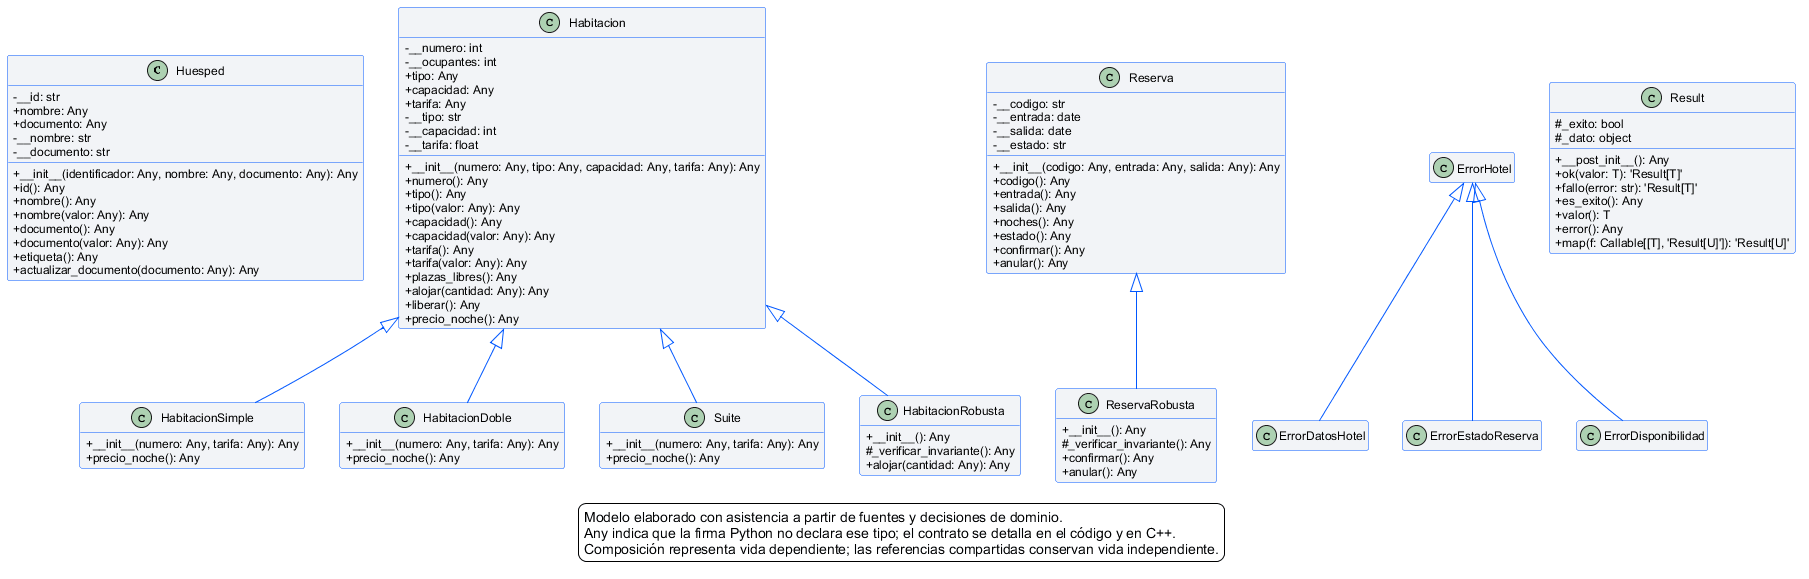

In [ ]:
import base64
from IPython.display import display, Image
display(Image(data=base64.b64decode('...')))


## resumen informe

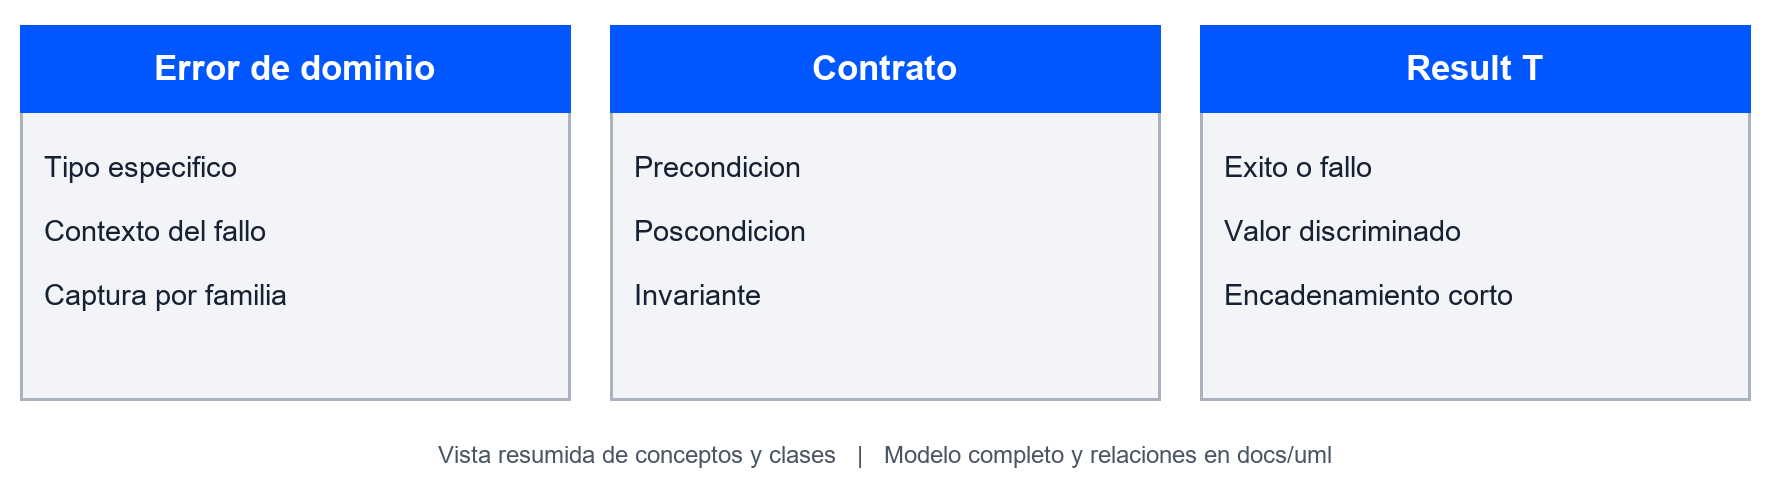

In [ ]:
import base64
from IPython.display import display, Image
display(Image(data=base64.b64decode('...')))
